In [ ]:
#Se importan las librerías a usar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import beta as beta_dist
from scipy.stats import t
from scipy.stats import norm
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc

#Se carga el dataset al notebook
df = pd.read_csv("ScreenTime vs MentalWellness.csv")
df = df.drop("Unnamed: 15", axis=1)
df.head()

,user_id,age,gender,occupation,work_mode,screen_time_hours,work_screen_hours,leisure_screen_hours,sleep_hours,sleep_quality_1_5,stress_level_0_10,productivity_0_100,exercise_minutes_per_week,social_hours_per_week,mental_wellness_index_0_100
0,U0001,33,Female,Employed,Remote,10.79,5.44,5.35,6.63,1,9.3,44.7,127,0.7,9.3
1,U0002,28,Female,Employed,In-person,7.40,0.37,7.03,8.05,3,5.7,78.0,74,2.1,56.2
2,U0003,35,Female,Employed,Hybrid,9.78,1.09,8.69,6.48,1,9.1,51.8,67,8.0,3.6
3,U0004,42,Male,Employed,Hybrid,11.13,0.56,10.57,6.89,1,10.0,37.0,0,5.7,0.0
4,U0005,28,Male,Student,Remote,13.22,4.09,9.13,5.79,1,10.0,38.5,143,10.1,0.0


## Media de Horas en Pantalla
Dado que nuestra hipótesis vincula el consumo digital con el bienestar mental, estimar la media poblacional del tiempo en pantalla nos permite establecer el comportamiento promedio de la muestra y utilizarlo como variable de control para analizar el estrés.

Definición del Parámetro: Media poblacional del tiempo diario total de uso de pantalla (en horas) para la población de personas con hábitos digitales.

Estimador Puntual ($\bar{X}$): Calculado como el promedio aritmético de las horas en pantalla.

Insesgadez: Como la media muestral es un estimador insesgado, el valor obtenido representa la mejor aproximación sin desviaciones sistemáticas del parámetro poblacional.

Eficiencia: Al ser el estimador de mínima varianza para este tipo de datos, garantiza la máxima precisión posible con nuestros 400 datos.

Estimador puntual de la media (x̄): 9.02 horas/día
Dispersión de la muestra (s): 2.49 horas


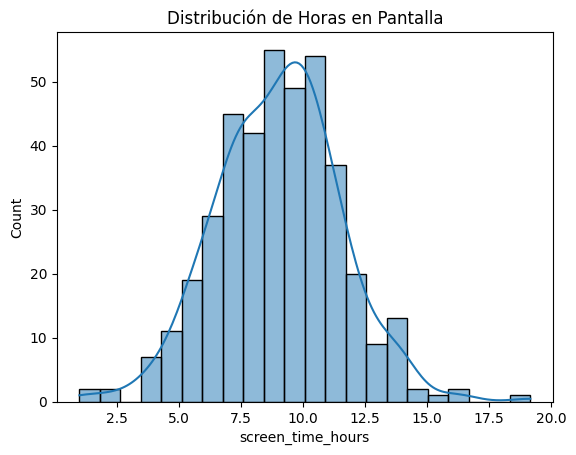

In [ ]:
# Calculamos la media muestral (Estimador Puntual)
media_pantalla = df['screen_time_hours'].mean()

# Calculamos la desviación estándar muestral
std_pantalla = df['screen_time_hours'].std()

print(f"Estimador puntual de la media (x̄): {media_pantalla:.2f} horas/día")
print(f"Dispersión de la muestra (s): {std_pantalla:.2f} horas")

sns.histplot(df['screen_time_hours'], kde=True)
plt.title("Distribución de Horas en Pantalla")
plt.show()

## Proporción de niveles altos de estrés
El análisis exploratorio reveló que el estrés no se distribuye uniformemente, sino que se concentra en valores críticos ($\ge 8$). Estimar la proporción poblacional de este grupo es vital para entender la prevalencia de un estado de "alerta" o estrés severo en la población.
Calculado como la frecuencia ($\hat{p}$) relativa de individuos con stress_level_0_10 >= 8 sobre el total de la muestra ($n=400$).

Consistencia: Nuestro estimador es consistente, lo que significa que el error de estimación disminuye al aumentar el tamaño de nuestra muestra, garantizando que el valor se aproxime al real.

Insesgadez: Al igual que la media, la proporción muestral es un estimador insesgado de la proporción poblacional, ofreciendo una medida directa y sin sesgos de la realidad observada.

Total de personas con estrés >= 8: 249
Estimador puntual de la proporción (p̂): 62.25%


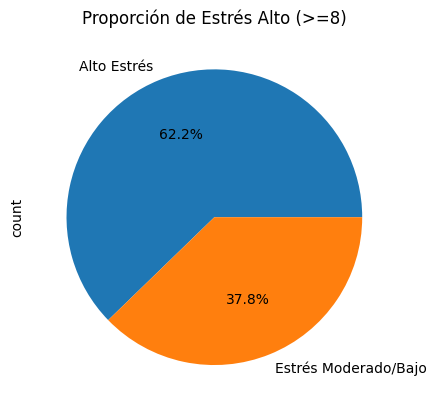

In [ ]:
# Definimos el umbral de 'alto estrés' según el análisis de la Entrega 1 (>= 8)
umbral_estres = 8

# Filtramos las filas que cumplen la condición
casos_altos = df[df['stress_level_0_10'] >= umbral_estres]

# Calculamos la proporción (casos de interés / total)
n = len(df)
proporcion_estres = len(casos_altos)/n

print(f"Total de personas con estrés >= 8: {len(casos_altos)}")
print(f"Estimador puntual de la proporción (p̂): {proporcion_estres:.2%}")

# Se grafican en un diagrama de pie los resultados
df['is_high_stress'] = df['stress_level_0_10'] >= umbral_estres
df['is_high_stress'].value_counts().plot(kind='pie', autopct='%1.1f%%', labels=['Alto Estrés', 'Estrés Moderado/Bajo'])
plt.title("Proporción de Estrés Alto (>=8)")
plt.show()

## Análisis Comparativo por Ocupación
Aquí realizamos un análisis multivariado. Agrupamos los datos por ocupación para detectar cómo el entorno (estudiante vs. empleado) influye en el uso de pantallas y el nivel de estrés.

In [ ]:
# Agrupar según ocupación
df['screen_time_hours'] = pd.to_numeric(df['screen_time_hours'], errors='coerce')
df['stress_level_0_10'] = pd.to_numeric(df['stress_level_0_10'], errors='coerce')

resumen_ocupacional = df.groupby('occupation').agg(
    media_pantalla=('screen_time_hours', 'mean'),
    proporcion_estres_alto=('stress_level_0_10', lambda x: (x >= 8).mean())
)

print("\n--- ANÁLISIS COMPARATIVO ---")
print(resumen_ocupacional.round(2))


--- ANÁLISIS COMPARATIVO ---
               media_pantalla  proporcion_estres_alto
occupation                                           
Employed                 8.89                    0.65
Retired                  7.37                    0.29
Self-employed            8.47                    0.53
Student                 10.33                    0.75
Unemployed               6.68                    0.26


Se puede observar, que en el grupo de los estudiantes, se presenta la mayor proporción de estrés alto y a su vez la mayor media de horas en pantalla.

## Diferencia entre proporciones de nivel de estrés según ocupación

Para comprender el impacto del estrés en los distintos grupos demográficos y visualizar cuáles son los segmentos más vulnerables, se evaluará la diferencia de proporciones de estrés crítico, es decir, mayor a 8, según cada ocupación. Se optó por utilizar proporciones en lugar de medias para evitar que la alta concentración de datos en los niveles máximos oculte el impacto real del problema.

El análisis se dividirá en dos segmentos poblacionales. El primero, la diferencia entre Empleados y Estudiantes, lo que permite comparar el nivel de tensión entre dos grupos sometidos a exigencias de rendimiento constante. El segundo, la diferencia entre Empleados y Desempleados, el cual contrastará la repercusión de enfrentar presiones y obligaciones diarias, frente al peso de la inactividad y la incertidumbre laboral.



El código a continuación permite dividir a la muestra en distintos dataframes separados por ocupación. Además se calcula la proporción del nivel de estrés crítico a través de la función proporción, que toma como parámetros un dataframe, el umbral de división, en este caso 8 y el nombre de la variable de la variable a estudiar, que corresponde al estrés.

In [ ]:
def proporcion(dataset, umbral, variable):
  contador = 0
  for valor in dataset[variable]:
      if(valor>=umbral):
          contador += 1
  return contador/len(dataset[variable])

# Agrupar ocupaciones
def agrupar_ocupacion(x):
    if x in ['Employed', 'Self-employed']:
        return 'Empleados'
    elif x in ['Unemployed', 'Retired']:
        return 'Desempleados'
    else:
        return 'Estudiantes'

df['grupo_ocupacion'] = df['occupation'].apply(agrupar_ocupacion)

# Separar en dataframes
df_empleados = df[df['grupo_ocupacion'] == 'Empleados']
df_desempleados = df[df['grupo_ocupacion'] == 'Desempleados']
df_estudiantes = df[df['grupo_ocupacion'] == 'Estudiantes']

# Calcular proporciones
proporcion_estres_emp = proporcion(df_empleados, 8, 'stress_level_0_10')
proporcion_estres_des = proporcion(df_desempleados, 8, 'stress_level_0_10')
proporcion_estres_est = proporcion(df_estudiantes, 8, 'stress_level_0_10')

print(f"Proporción de Estrés Crítico en Empleados: {proporcion_estres_emp:.3f}")
print(f"Proporción de Estrés Crítico en Desempleados: {proporcion_estres_des:.3f}")
print(f"Proporción de Estrés Crítico en Estudiantes: {proporcion_estres_est:.3f}")

Proporción de Estrés Crítico en Empleados: 0.627
Proporción de Estrés Crítico en Desempleados: 0.268
Proporción de Estrés Crítico en Estudiantes: 0.748


A partir de la muestra obtenida, se calcularon los estimadores puntuales para

---

la proporción de estrés crítico en cada grupo demográfico, obteniendo un 0.627 (62.7%) para Empleados, un 0.748 (74.8%) para Estudiantes y un 0.268 (26.8%) para Desempleados.

# Bootstrap


In [ ]:
def remuestreo_bootstrap_medias(dataset, n, columna):
    np.random.seed(777)
    datos = dataset[columna].values
    medias_remuestreo = []
    i=0
    while(i<10000):
        indices = np.random.randint(0,n, size=n)
        remuestras = datos[indices]
        medias_remuestreo.append(remuestras.mean())
        i=i+1
    return medias_remuestreo

def remuestreo_bootstrap_proporciones(dataset, n, columna, umbral):
    np.random.seed(777)
    datos = dataset[columna].values
    proporciones_remuestreo = []
    i=0
    while(i<10000):
        contador = 0
        indices = np.random.randint(0, n, size = n)
        remuestras = datos[indices]
        for valor in remuestras:
            if(valor>=umbral):
                contador = contador + 1
        proporciones_remuestreo.append(contador/n)
        i = i+1
    return proporciones_remuestreo

def remuestreo_bootstrap_diferencia_proporciones(dataset1, dataset2, columna, umbral):
    np.random.seed(777)
    datos1 = dataset1[columna].values
    datos2 = dataset2[columna].values
    dif_proporciones_remuestreo = []
    i=0
    while(i<10000):
        contador1 = 0
        contador2 = 0
        indices1 = np.random.randint(0, len(datos1), size = len(datos1))
        indices2 = np.random.randint(0, len(datos2), size = len(datos2))
        remuestras1 = datos1[indices1]
        remuestras2 = datos2[indices2]
        for valor in remuestras1:
            if(valor>=umbral):
                contador1 = contador1 + 1
        for valor in remuestras2:
            if(valor>=umbral):
                contador2 = contador2 + 1
        dif_proporciones_remuestreo.append(contador1/len(datos1) - contador2/len(datos2))
        i = i+1
    return dif_proporciones_remuestreo

def remuestreo_bootstrap_correlacion_pearson(dataset, n, columna1, columna2):
    np.random.seed(777)
    datos1 = dataset[columna1].values
    datos2 = dataset[columna2].values
    correlacion_pearson_remuestreo = []
    i=0
    while(i<10000):
        indices = np.random.randint(0, n, size=n)
        remuestras1 = datos1[indices]
        remuestras2 = datos2[indices]
        correlacion_pearson_remuestreo.append(np.corrcoef(remuestras1, remuestras2)[0, 1])
        i = i+1
    return correlacion_pearson_remuestreo

def remuestreo_bootstrap_correlacion_spearman(dataset, n, columna1, columna2):
    np.random.seed(777)
    datos1 = dataset[columna1].values
    datos2 = dataset[columna2].values
    correlacion_spearman_remuestreo = []
    i=0
    while(i<10000):
        indices = np.random.randint(0, n, size=n)
        remuestras1 = datos1[indices]
        remuestras2 = datos2[indices]
        correlacion_spearman_remuestreo.append(stats.spearmanr(remuestras1, remuestras2).statistic)
        i = i+1
    return correlacion_spearman_remuestreo

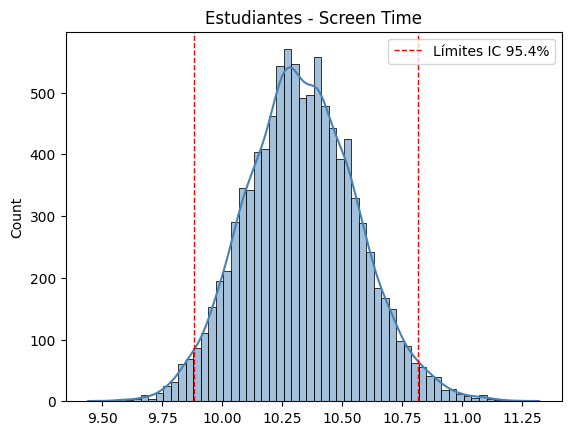

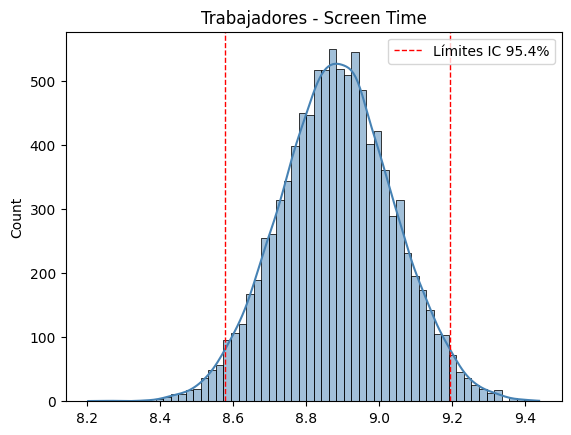

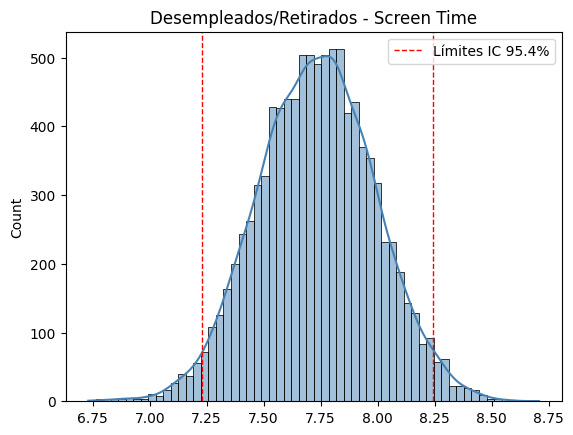

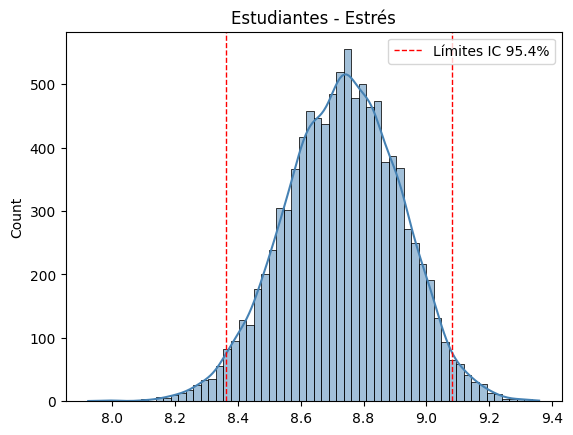

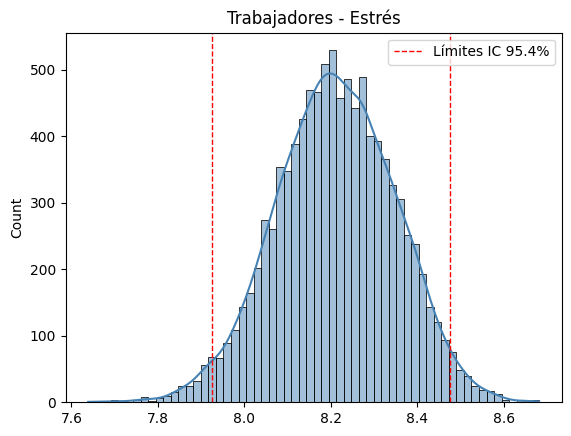

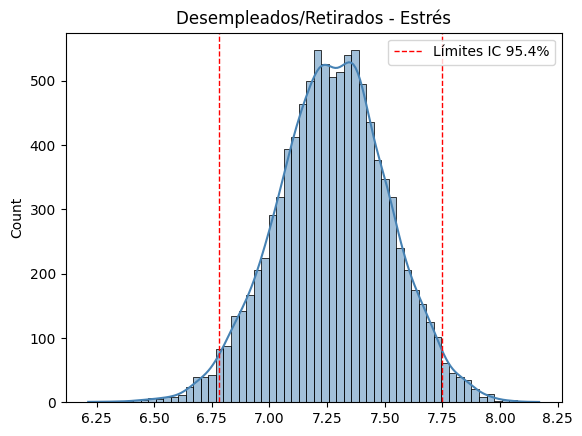

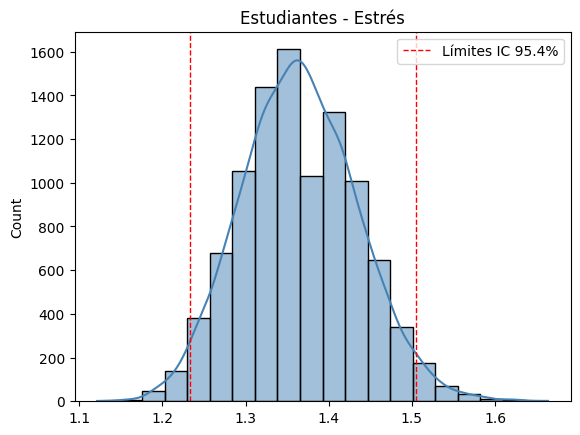

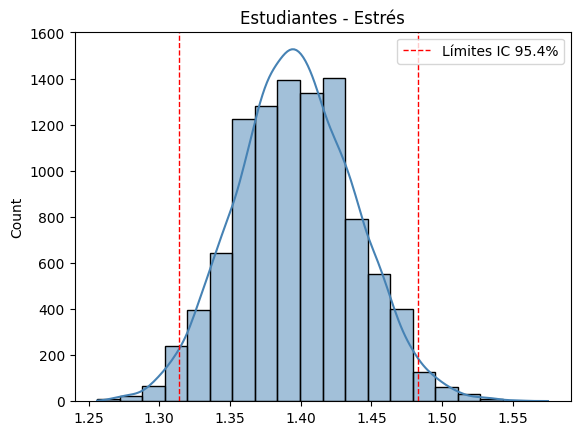

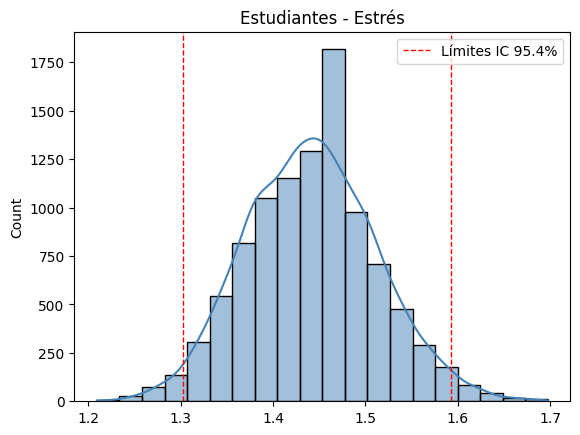

TIEMPO EN PANTALLA


Media bootstrap Estudiantes tiempo en pantalla: 10.333457943925236 10.332129140186877
Media bootstrap Trabajadores tiempo en pantalla: 8.886135265700485 8.883833125603866
Media bootstrap Desemp/Ret tiempo en pantalla: 7.730813953488374 7.7330295930232475


Incertidumbre Estudiantes tiempo en pantalla: 0.9347771028037393
Incertidumbre Trabajadores tiempo en pantalla: 0.6165284057971032
Incertidumbre Desemp/Ret tiempo en pantalla: 1.010351511627909


ESTRES


Media bootstrap Estudiantes estres 8.733644859813085 8.73262355140188
Media bootstrap Trabajadores estres: 8.214492753623187 8.211204589372043
Media bootstrap Desemp/Ret estres: 7.270930232558141 7.273857441860438


Incertidumbre Estudiantes estres: 0.7206037383177577
Incertidumbre Trabajadores estres: 0.5502526570048287
Incertidumbre Desemp/Ret estres: 0.9651162790697665


CALIDAD DEL SUEÑO


Media bootstrap Estudiantes calidad del sueño: 1.3644859813084111 1.3649271028037564
Media bootstrap Trabajadores calida

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv("ScreenTime vs MentalWellness.csv")
def agrupar(x):
    x = str(x).lower().strip()
    if x == 'student':
        return 'Estudiantes'
    elif x == 'employed':
        return 'Trabajadores'
    else:
        return 'Desempleados/Retirados'

import numpy as np

df['grupo'] = df['occupation'].apply(agrupar)
n_est = len(df[df['grupo'] == 'Estudiantes'])
n_trab = len(df[df['grupo'] == 'Trabajadores'])
n_des = len(df[df['grupo'] == 'Desempleados/Retirados'])

#subdatasets
df_est = df[df['grupo'] == 'Estudiantes']
df_trab = df[df['grupo'] == 'Trabajadores']
df_des = df[df['grupo'] == 'Desempleados/Retirados']

#tiempo en pantalla
medias_est = remuestreo_bootstrap_medias(df_est, n_est, 'screen_time_hours')
medias_trab = remuestreo_bootstrap_medias(df_trab, n_trab, 'screen_time_hours')
medias_des = remuestreo_bootstrap_medias(df_des, n_des, 'screen_time_hours')

#estres
medias_est_estres = remuestreo_bootstrap_medias(df_est, n_est, 'stress_level_0_10')
medias_trab_estres = remuestreo_bootstrap_medias(df_trab, n_trab, 'stress_level_0_10')
medias_des_estres = remuestreo_bootstrap_medias(df_des, n_des, 'stress_level_0_10')

#calidad del sueño
medias_est_sueno = remuestreo_bootstrap_medias(df_est, n_est, 'sleep_quality_1_5')
medias_trab_sueno = remuestreo_bootstrap_medias(df_trab, n_trab, 'sleep_quality_1_5')
medias_des_sueno = remuestreo_bootstrap_medias(df_des, n_des, 'sleep_quality_1_5')

#calculamos el IC para tiempo en pantalla
lim_inf_t1 = np.percentile(medias_est, 2.3)
lim_sup_t1 = np.percentile(medias_est, 97.7)

lim_inf_t2 = np.percentile(medias_trab, 2.3)
lim_sup_t2 = np.percentile(medias_trab, 97.7)

lim_inf_t3 = np.percentile(medias_des, 2.3)
lim_sup_t3 = np.percentile(medias_des, 97.7)

#calculamos el IC para estres
lim_inf_e1 = np.percentile(medias_est_estres, 2.3)
lim_sup_e1 = np.percentile(medias_est_estres, 97.7)

lim_inf_e2 = np.percentile(medias_trab_estres, 2.3)
lim_sup_e2 = np.percentile(medias_trab_estres, 97.7)

lim_inf_e3 = np.percentile(medias_des_estres, 2.3)
lim_sup_e3 = np.percentile(medias_des_estres, 97.7)

#calculamos el IC para calidad del sueño
lim_inf_s1 = np.percentile(medias_est_sueno, 2.3)
lim_sup_s1 = np.percentile(medias_est_sueno, 97.7)

lim_inf_s2 = np.percentile(medias_trab_sueno, 2.3)
lim_sup_s2 = np.percentile(medias_trab_sueno, 97.7)

lim_inf_s3 = np.percentile(medias_des_sueno, 2.3)
lim_sup_s3 = np.percentile(medias_des_sueno, 97.7)

#calculamos la incertidumbre para el tiempo en pantalla

incertidumbre_t1 = lim_sup_t1 - lim_inf_t1

incertidumbre_t2 = lim_sup_t2 - lim_inf_t2

incertidumbre_t3 = lim_sup_t3 - lim_inf_t3

#calculamos la incertidumbre para el estres

incertidumbre_e1 = lim_sup_e1 - lim_inf_e1

incertidumbre_e2 = lim_sup_e2 - lim_inf_e2

incertidumbre_e3 = lim_sup_e3 - lim_inf_e3

#calculamos la incertidumbre para el sueño

incertidumbre_s1 = lim_sup_s1 - lim_inf_s1

incertidumbre_s2 = lim_sup_s2 - lim_inf_s2

incertidumbre_s3 = lim_sup_s3 - lim_inf_s3

#graficamos tiempo en pantalla

sns.histplot(medias_est, bins=60, kde=True, color='steelblue')
plt.title("Estudiantes - Screen Time")
plt.axvline(lim_inf_t1, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_t1, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()

sns.histplot(medias_trab, bins=60, kde=True, color='steelblue')
plt.title("Trabajadores - Screen Time")
plt.axvline(lim_inf_t2, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_t2, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()

sns.histplot(medias_des, bins=60, kde=True, color='steelblue')
plt.title("Desempleados/Retirados - Screen Time")
plt.axvline(lim_inf_t3, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_t3, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()


#graficamos estres

sns.histplot(medias_est_estres, bins=60, kde=True, color='steelblue')
plt.title("Estudiantes - Estrés")
plt.axvline(lim_inf_e1, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_e1, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()

sns.histplot(medias_trab_estres, bins=60, kde=True, color='steelblue')
plt.title("Trabajadores - Estrés")
plt.axvline(lim_inf_e2, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_e2, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()

sns.histplot(medias_des_estres, bins=60, kde=True, color='steelblue')
plt.title("Desempleados/Retirados - Estrés")
plt.axvline(lim_inf_e3, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_e3, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()

#graficamos calidad del sueño
sns.histplot(medias_est_sueno, bins=20, kde=True, color='steelblue')
plt.title("Estudiantes - Sueño")
plt.title("Estudiantes - Estrés")
plt.axvline(lim_inf_s1, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_s1, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()

sns.histplot(medias_trab_sueno, bins=20, kde=True, color='steelblue')
plt.title("Trabajadores - Sueño")
plt.title("Estudiantes - Estrés")
plt.axvline(lim_inf_s2, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_s2, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()

sns.histplot(medias_des_sueno, bins=20, kde=True, color='steelblue')
plt.title("Desempleados/Retirados - Sueño")
plt.title("Estudiantes - Estrés")
plt.axvline(lim_inf_s3, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_s3, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')
plt.show()


#tiempo en pantalla
print("TIEMPO EN PANTALLA")
print("\n")
print("Media bootstrap Estudiantes tiempo en pantalla:", df_est['screen_time_hours'].mean(), sum(medias_est)/len(medias_est))
print("Media bootstrap Trabajadores tiempo en pantalla:", df_trab['screen_time_hours'].mean(), sum(medias_trab)/len(medias_trab))
print("Media bootstrap Desemp/Ret tiempo en pantalla:", df_des['screen_time_hours'].mean(), sum(medias_des)/len(medias_des))
print("\n")
print(f"Incertidumbre Estudiantes tiempo en pantalla: {incertidumbre_t1}")
print(f"Incertidumbre Trabajadores tiempo en pantalla: {incertidumbre_t2}")
print(f"Incertidumbre Desemp/Ret tiempo en pantalla: {incertidumbre_t3}")
print("\n")

#estres
print("ESTRES")
print("\n")
print("Media bootstrap Estudiantes estres", df_est['stress_level_0_10'].mean(), sum(medias_est_estres)/len(medias_est_estres))
print("Media bootstrap Trabajadores estres:", df_trab['stress_level_0_10'].mean(), sum(medias_trab_estres)/len(medias_trab_estres))
print("Media bootstrap Desemp/Ret estres:", df_des['stress_level_0_10'].mean(), sum(medias_des_estres)/len(medias_des_estres))
print("\n")
print(f"Incertidumbre Estudiantes estres: {incertidumbre_e1}")
print(f"Incertidumbre Trabajadores estres: {incertidumbre_e2}")
print(f"Incertidumbre Desemp/Ret estres: {incertidumbre_e3}")
print("\n")

#calidad del sueño
print("CALIDAD DEL SUEÑO")
print("\n")
print("Media bootstrap Estudiantes calidad del sueño:", df_est['sleep_quality_1_5'].mean(), sum(medias_est_sueno)/len(medias_est_sueno))
print("Media bootstrap Trabajadores calidad del sueño:", df_trab['sleep_quality_1_5'].mean(), sum(medias_trab_sueno)/len(medias_trab_sueno))
print("Media bootstrap Desemp/Ret calidad del sueño:", df_des['sleep_quality_1_5'].mean(), sum(medias_des_sueno)/len(medias_des_sueno))
print("\n")
print(f"Incertidumbre Estudiantes calidad del sueño: {incertidumbre_s1}")
print(f"Incertidumbre Trabajadores calidad del sueño: {incertidumbre_s2}")
print(f"Incertidumbre Desemp/Ret calidad del sueño: {incertidumbre_s3}")

Para cada una de las medias según la ocupación, es posible notar que los límites de los intervalos de confianza rondan en valores muy cercanos al obtenido en sus estimadores, además ningún intervalo sobrepasa el valor nulo, por lo tanto, confirma matemáticamente que existe un efecto real.

## Bootstrap de la Diferencia de Proporción de Estrés Crítico entre Empleados y Estudiantes

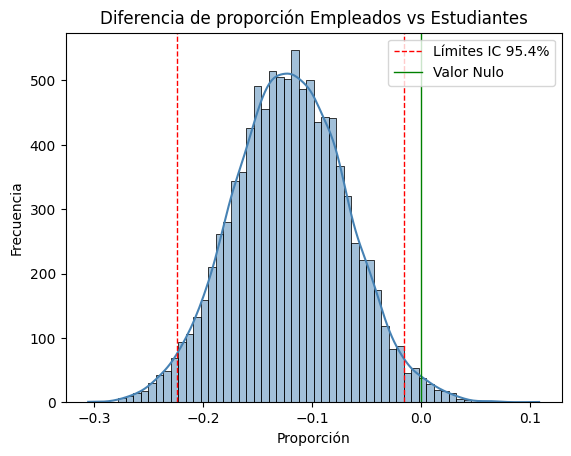

Límite inferior del IC -0.22411960391633282
Límite superior del IC -0.016089563862928532
Incertidumbre: 0.20803004005340428


In [ ]:
dif_prop_emp_est = remuestreo_bootstrap_diferencia_proporciones(df_empleados, df_estudiantes, 'stress_level_0_10', 8)

sns.histplot(dif_prop_emp_est, bins=60, kde=True, color='steelblue')

lim_inf_d1 = np.percentile(dif_prop_emp_est, 2.3)
lim_sup_d1 = np.percentile(dif_prop_emp_est, 97.7)

incertidumbre_d1 = lim_sup_d1 - lim_inf_d1

plt.title('Diferencia de proporción Empleados vs Estudiantes')
plt.xlabel('Proporción')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_d1, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_d1, color='red', linestyle='dashed', linewidth=1)
plt.axvline(0, color='green', linewidth=1, label='Valor Nulo')
plt.legend(loc='upper right')

plt.show()

print(f"Límite inferior del IC {lim_inf_d1}")
print(f"Límite superior del IC {lim_sup_d1}")
print(f"Incertidumbre: {incertidumbre_d1}")

El estimador indicó que los estudiantes presentan un 12% más de exposición al estrés crítico respecto a los empleados. A partir del Bootstrap, se pudo obtener el intervalo de confianza al 95.4%, correspondiente a [-0.224, -0.016]. El intervalo presenta algunos valores alejados, que indican que existe un margen de error respecto al estimador puntual, sin embargo, es completamente negativo, es decir, excluye el cero, por lo que es posible concluir que la población estudiantil es más vulnerable al estrés severo que el grupo de trabajadores.

## Bootstrap de la Diferencia de Proporción de Estrés Crítico entre Empleados y Desempleados

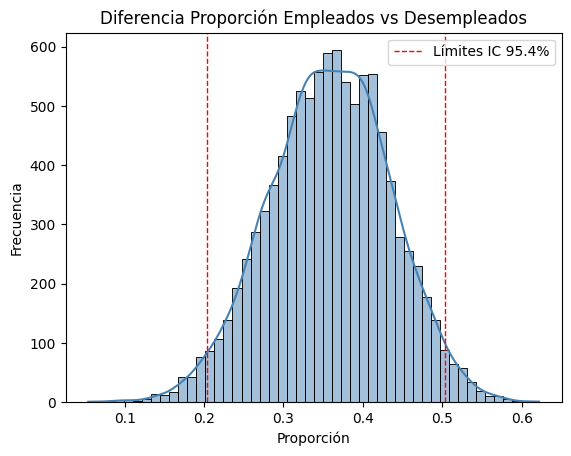

Límite inferior del IC 0.20383275261324046
Límite superior del IC 0.5038714672861014
Incertidumbre: 0.300038714672861


In [ ]:
dif_prop_emp_des = remuestreo_bootstrap_diferencia_proporciones(df_empleados, df_desempleados, 'stress_level_0_10', 8)

sns.histplot(dif_prop_emp_des, bins=50, kde=True, color='steelblue')

lim_inf_d2 = np.percentile(dif_prop_emp_des, 2.3)
lim_sup_d2 = np.percentile(dif_prop_emp_des, 97.7)

incertidumbre_d2 = lim_sup_d2 - lim_inf_d2

plt.title('Diferencia Proporción Empleados vs Desempleados')
plt.xlabel('Proporción')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_d2, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_d2, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')

plt.show()

print(f"Límite inferior del IC {lim_inf_d2}")
print(f"Límite superior del IC {lim_sup_d2}")
print(f"Incertidumbre: {incertidumbre_d2}")

Se obtuvo un estimador puntual que indica que los empleados están un 36% más expuestos al estrés crítico frente a los desempleados. El intervalo de confianza al 95.4% calculado oscila entre [0.204, 0.504], cuyos valores son siempre positivos y presentan una leve variación respecto al estimador. Al no incluir al cero, se confirma estadísticamente que las presiones laborales superan considerablemente al impacto de la inactividad laboral.

## Bootstrap de la Correlación entre Estrés y Horas en pantalla para Empleados

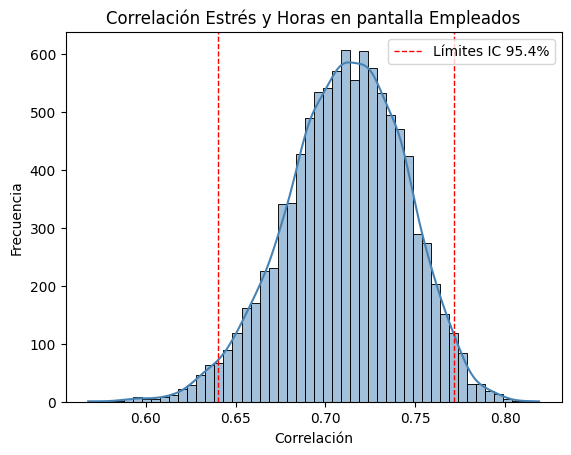

Límite inferior del IC 0.640446579643978
Límite superior del IC 0.7715042823299342
Incertidumbre: 0.13105770268595618


In [ ]:
corrs_pantalla_emp = remuestreo_bootstrap_correlacion_spearman(df_empleados, len(df_empleados), 'stress_level_0_10', 'screen_time_hours')

sns.histplot(corrs_pantalla_emp, bins=50, kde=True, color='steelblue')

lim_inf_c1 = np.percentile(corrs_pantalla_emp, 2.3)
lim_sup_c1 = np.percentile(corrs_pantalla_emp, 97.7)

incertidumbre_c1 = lim_sup_c1 - lim_inf_c1

plt.title('Correlación Estrés y Horas en pantalla Empleados')
plt.xlabel('Correlación')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_c1, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_c1, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')

plt.show()

print(f"Límite inferior del IC {lim_inf_c1}")
print(f"Límite superior del IC {lim_sup_c1}")
print(f"Incertidumbre: {incertidumbre_c1}")

Para este caso, el estimador puntual presentó una correlación de 0.713. Luego, al aplicar el método de Bootstrap, el intervalo de confianza al 95.4% obtenido fue [0.640, 0.772], donde sus extremos no varían demasiado respecto al estadístico, lo que permite verificar la confiabilidad del mismo y además afirmar que el estrés mantiene una relación moderada-fuerte con respecto a las horas en pantalla en empleados.

## Bootstrap de la Correlación entre Estrés y Horas en pantalla para Desempleados

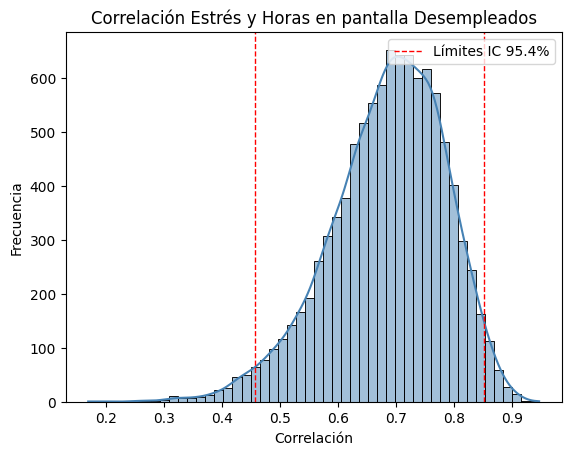

Límite inferior del IC 0.45665102528028145
Límite superior del IC 0.8516621620549532
Incertidumbre: 0.3950111367746717


In [ ]:
corrs_pantalla_des = remuestreo_bootstrap_correlacion_spearman(df_desempleados, len(df_desempleados), 'stress_level_0_10', 'screen_time_hours')

sns.histplot(corrs_pantalla_des, bins=50, kde=True, color='steelblue')

lim_inf_c2 = np.percentile(corrs_pantalla_des, 2.3)
lim_sup_c2 = np.percentile(corrs_pantalla_des, 97.7)

incertidumbre_c2 = lim_sup_c2 - lim_inf_c2

plt.title('Correlación Estrés y Horas en pantalla Desempleados')
plt.xlabel('Correlación')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_c2, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_c2, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')


plt.show()

print(f"Límite inferior del IC {lim_inf_c2}")
print(f"Límite superior del IC {lim_sup_c2}")
print(f"Incertidumbre: {incertidumbre_c2}")

El estadístico obtenido para esta correlación fue de 0.694 y su intervalo de confianza al 95.4% varía entre [0.457, 0.852], valor muy alejado del cero. El resultado indica que como mínimo existe una relación moderada entre el estrés y las horas en pantalla para desempleados.

## Bootstrap de la Correlación entre Estrés y Horas en pantalla para Estudiantes

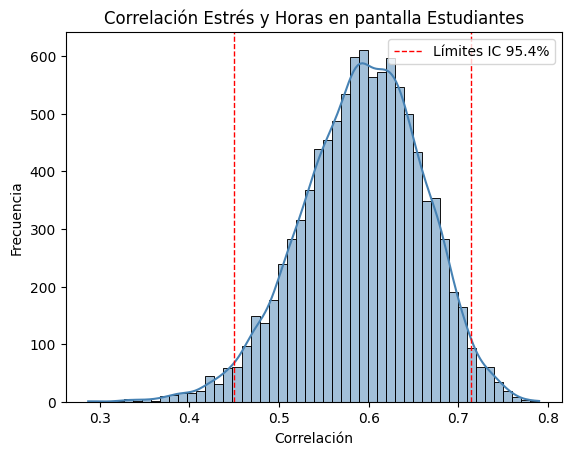

Límite inferior del IC 0.44944035650780284
Límite superior del IC 0.7143055420626353
Incertidumbre: 0.26486518555483246


In [ ]:
corrs_pantalla_est = remuestreo_bootstrap_correlacion_spearman(df_estudiantes, len(df_estudiantes), 'stress_level_0_10', 'screen_time_hours')

sns.histplot(corrs_pantalla_est, bins=50, kde=True, color='steelblue')

lim_inf_c3 = np.percentile(corrs_pantalla_est, 2.3)
lim_sup_c3 = np.percentile(corrs_pantalla_est, 97.7)

incertidumbre_c3 = lim_sup_c3 - lim_inf_c3

plt.title('Correlación Estrés y Horas en pantalla Estudiantes')
plt.xlabel('Correlación')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_c3, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_c3, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')

plt.show()

print(f"Límite inferior del IC {lim_inf_c3}")
print(f"Límite superior del IC {lim_sup_c3}")
print(f"Incertidumbre: {incertidumbre_c3}")

Respecto a los estudiantes, el estimado calculado para la correlación fue de 0.596 y el intervalo de confianza al 95.4% de [0.449, 0.714], presentando una variación inferior a 0.12, lo que indica que, para este estimador, la influencia de las horas en pantalla en el estrés no varía demasiado y muestra como mínimo relaciones cercanas a las moderadas.

## Bootstrap de la Correlación entre Estrés y  Calidad del sueño para Empleados

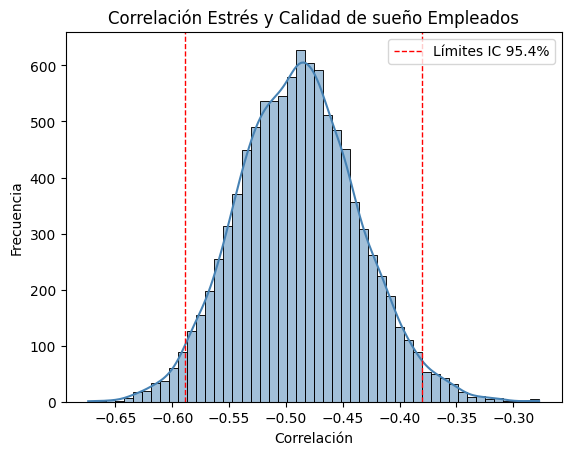

Límite inferior del IC -0.5891702552576426
Límite superior del IC -0.38011224326787857
Incertidumbre: 0.20905801198976398


In [ ]:
corrs_sueño_emp = remuestreo_bootstrap_correlacion_spearman(df_empleados, len(df_empleados), 'stress_level_0_10', 'sleep_quality_1_5')

sns.histplot(corrs_sueño_emp, bins=50, kde=True, color='steelblue')

lim_inf_c4 = np.percentile(corrs_sueño_emp, 2.3)
lim_sup_c4 = np.percentile(corrs_sueño_emp, 97.7)

incertidumbre_c4 = lim_sup_c4 - lim_inf_c4

plt.title('Correlación Estrés y Calidad de sueño Empleados')
plt.xlabel('Correlación')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_c4, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_c4, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')

plt.show()

print(f"Límite inferior del IC {lim_inf_c4}")
print(f"Límite superior del IC {lim_sup_c4}")
print(f"Incertidumbre: {incertidumbre_c4}")

Se calculó un estimador puntual de -0.490 y su intervalo de confianza al 95.4% obtenido mediante el Bootstraping oscila entre [-0.589, -0.380], mostrando una cercanía con el estadístico e indicando que la calidad sueño puede tener una incidencia negativa de carácter moderado sobre el estrés de los empleados.

## Bootstrap de la Correlación entre Estrés y  Calidad del sueño para Desempleados

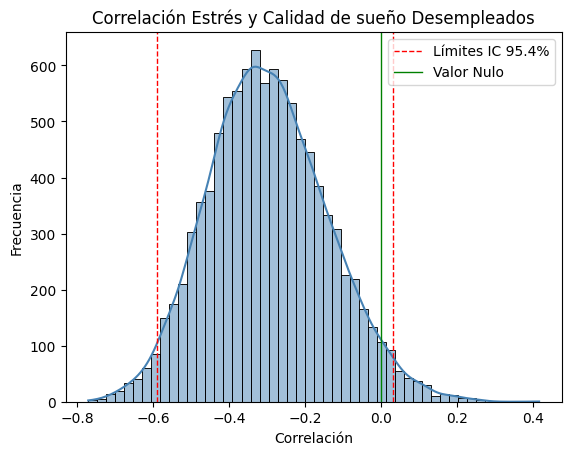

Límite inferior del IC -0.5900900620874645
Límite superior del IC 0.03232564823994006
Incertidumbre: 0.6224157103274046


In [ ]:
corrs_sueño_des = remuestreo_bootstrap_correlacion_spearman(df_desempleados, len(df_desempleados), 'stress_level_0_10', 'sleep_quality_1_5')

sns.histplot(corrs_sueño_des, bins=50, kde=True, color='steelblue')

lim_inf_c5 = np.percentile(corrs_sueño_des, 2.3)
lim_sup_c5 = np.percentile(corrs_sueño_des, 97.7)

incertidumbre_c5 = lim_sup_c5 - lim_inf_c5

plt.title('Correlación Estrés y Calidad de sueño Desempleados')
plt.xlabel('Correlación')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_c5, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_c5, color='red', linestyle='dashed', linewidth=1)
plt.axvline(0, color='green', linewidth=1, label='Valor Nulo')
plt.legend(loc='upper right')

plt.show()

print(f"Límite inferior del IC {lim_inf_c5}")
print(f"Límite superior del IC {lim_sup_c5}")
print(f"Incertidumbre: {incertidumbre_c5}")

El estadístico obtenido fue de -0.30 y su intervalo de confianza al 95.4% varía entre [-0.590, 0.03]. Para este caso ocurre que el IC sobrepasa el cero, lo que indica que se carece de evidencia suficiente para afirmar que la calidad del sueño impacte el nivel de estrés en la población general de desempleados. Este acontecimiento puede deberse a distintos factores como, el tamaño de la muestra o respuestas demasiado variadas, resultando en un estimador que no es informativo.

## Bootstrap de la Correlación entre Estrés y  Calidad del sueño para Estudiantes

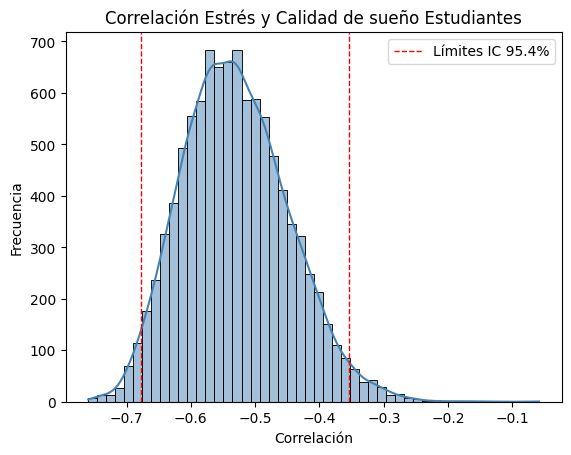

Límite inferior del IC -0.6768596052377545
Límite superior del IC -0.35390082117786
Incertidumbre: 0.3229587840598945


In [ ]:
corrs_sueño_est = remuestreo_bootstrap_correlacion_spearman(df_estudiantes, len(df_estudiantes), 'stress_level_0_10', 'sleep_quality_1_5')

sns.histplot(corrs_sueño_est, bins=50, kde=True, color='steelblue')

lim_inf_c6 = np.percentile(corrs_sueño_est, 2.3)
lim_sup_c6 = np.percentile(corrs_sueño_est, 97.7)

incertidumbre_c6 = lim_sup_c6 - lim_inf_c6

plt.title('Correlación Estrés y Calidad de sueño Estudiantes')
plt.xlabel('Correlación')
plt.ylabel('Frecuencia')

plt.axvline(lim_inf_c6, color='red', linestyle='dashed', linewidth=1, label='Límites IC 95.4%')
plt.axvline(lim_sup_c6, color='red', linestyle='dashed', linewidth=1)
plt.legend(loc='upper right')

plt.show()

print(f"Límite inferior del IC {lim_inf_c6}")
print(f"Límite superior del IC {lim_sup_c6}")
print(f"Incertidumbre: {incertidumbre_c6}")

Para los estudiantes se calculó un estimador de -0.532, luego a través del Bootstraping, el intervalo de confianza al 95.4% resultante fue de [-0.677, -0.354], en el cual existen algunas variaciones respecto al estadístico, sin embargo, es posible confirmar la influencia negativa entre ambas variables.

## Análisis de los intervalos de confianza

Aunque algunas distribuciones bootstrap presentan asimetría, por la propiedad asintótica, la variabilidad de los estimadores disminuye aproximadamente a razón de $\frac{1}{√n}$. Por ello, para reducir la incertidumbre en un $55%$, se requiere incrementar el tamaño muestral en un factor aproximado de $\frac{1}{0.45^2}$, es decir, para nuestro caso, se debería incrementar la muestra en $1572$ personas, para así obtener un total de $1976$, lo que es independiente de la forma específica de la distribución bootstrap.

Si la muestra es fija, dado un nivel de confianza del $95.4%$, el área bajo la curva se encuentra a 2 desviaciones estándar del centro ($Z=2$). Por lo tanto, aplicando la proporción de $0.45$ a Z se obtiene un nuevo factor $Z = 0.9$, cuya probabilidad acumulada es de aproximadamente 0,81. Entonces el nivel de confianza sería $0.81−(1−0.81)=0.62$ y por lo tanto la nueva significancia sería de $0.38$.
Cabe destacar que la reducción de la incertidumbre mediante cambios en el nivel de significancia se obtiene disminuyendo la cobertura del intervalo de confianza, es decir, utilizando percentiles bootstrap más cercanos al centro de la distribución. Este razonamiento no requiere asumir normalidad y es válido también para distribuciones bootstrap asimétricas.

Respecto a la viabilidad práctica modificar la significancia supone una alternativa mucho más fácil de ejecutar, ya que no requiere de actividades adicionales, a diferencia del aumento del tamaño muestral, que implicaría encuestar a $1576$ personas más. Sin embargo, la principal desventaja de modificar la significancia es que se pierde seguridad, porque el error aumentaría en un $37%$, lo que daría paso a posibles conclusiones inválidas. Por lo tanto, en términos de interpretación estadística siempre será mejor obtener más datos, debido a que se mantendría el nivel de confianza en un $95.4%$. Entonces, considerando el contexto de una investigación sobre salud mental y estrés, es preferible aumentar el tamaño de la muestra, para así evitar caer en afirmaciones erradas sobre un aspecto tan importante como lo es el bienestar de las personas.

# Ajuste de bondad
Para modelar la variable estrés mediante una distribución Beta, se estimaron sus parámetros utilizando el método de los momentos.

Primero se normalizaron la media y la varianza:

$$
\mu = \frac{\bar{x}}{10}
$$

$$
\sigma^2 = \frac{s^2}{100}
$$

Luego se calculó:

$$
t = \frac{\mu(1-\mu)}{\sigma^2} - 1
$$

y finalmente los parámetros de la distribución Beta:

$$
\alpha = \mu \cdot t
$$

$$
\beta = (1-\mu)\cdot t
$$

Con estos parámetros se ajustó una distribución Beta a los datos de estrés y posteriormente se aplicó la prueba de bondad de ajuste de Kolmogorov-Smirnov.

Se investigaron las pruebas Kolmogorov-Smirnov, Anderson-Darling y Chi-cuadrado. Finalmente se seleccionó Kolmogorov-Smirnov debido a que la variable estrés es cuantitativa, la muestra posee 400 observaciones y la prueba permite comparar directamente los datos observados con una distribución teórica sin necesidad de agruparlos.

Los resultados mostraron un estadístico D = 0.3375 para la distribución Beta y D = 0.1884 para la distribución Normal. Los valores p obtenidos fueron 3.8×10⁻⁴¹ y 6.7×10⁻¹³, respectivamente.

Considerando un nivel de significancia α = 0.05, en ambos casos se obtuvo p < α, por lo que se rechazó la hipótesis nula de que los datos provienen exactamente de dichas distribuciones. Esto indica que ninguna de las distribuciones propuestas representa perfectamente el comportamiento observado en los niveles de estrés.

Sin embargo, la distribución Normal presentó un mejor ajuste relativo al obtener un estadístico D menor. A pesar de ello, la distribución Beta fue utilizada en las simulaciones Monte Carlo debido a que el nivel de estrés está acotado entre 0 y 10, característica que la hace apropiada para representar este tipo de variable.

Finalmente, estos resultados son consistentes con los intervalos de confianza obtenidos mediante bootstrap, ya que dicho método no requiere asumir una distribución teórica específica. Por lo tanto, aunque ninguna distribución reprodujo perfectamente los datos observados, las estimaciones obtenidas previamente mantienen su validez estadística.

### Estadístico de Kolmogorov-Smirnov

La prueba de Kolmogorov-Smirnov compara la distribución acumulada observada con una distribución acumulada teórica mediante el estadístico:

$$
D = \max_x |F_n(x)-F(x)|
$$

donde:

- $F_n(x)$: distribución acumulada empírica de los datos.
- $F(x)$: distribución acumulada teórica.
- $D$: máxima diferencia entre ambas distribuciones.

Mientras menor sea el valor de $D$, mejor será el ajuste de la distribución teórica a los datos observados.

En este estudio se obtuvo:

$$
D_{Beta}=0.3375
$$

$$
D_{Normal}=0.1884
$$

Por lo tanto, la distribución Normal presentó un mejor ajuste relativo al obtener un valor de $D$ menor.

# Test de Hipótesis

## Test de comparación de medias

La primera situación planteada, es que en promedio, los estudiantes poseen una media de estrés más alta que los no estudiantes. De esta forma, la hipótesis nula y la hipótesis alternativa quedan definidas de la siguiente forma

$$
H_0: 𝜇_{\text{estudiantes}} = 𝜇_{\text{no estudiantes}}
$$

$$
H_1: 𝜇_{\text{estudiantes}} > 𝜇_{\text{no estudiantes}}
$$


Para trabajar esta hipótesis, se decidió trabajar con varianza desconocida pero igual, es decir

$$
\sigma^2_{\text{estudiantes}} = \sigma^2_{\text{no estudiantes}}
$$

Este planteamiento viene de un desconocimiento poblacional de este parámetro, sin embargo, como ambos datos provienen de la misma población, se decidió usar el supuesto de las varianzas iguales.

Para esta situación, el estadístico a usar es el t-student, además, se usará una significancia de $α=0,05$, de esta forma, dicha distribución sigue la siguiente ecuación

<br>
$$
T=
\frac{
(\bar X_{\text{estudiantes}}-\bar X_{\text{no estudiantes}})
-
(\mu_{\text{estudiantes}}-\mu_{\text{no estudiantes}})
}
{
S_p
\sqrt{
\frac{1}{n_{\text{estudiantes}}}
+
\frac{1}{n_{\text{no estudiantes}}}
}
}
\sim
t_{n_{\text{estudiantes}}+n_{\text{no estudiantes}}-2}
$$
<br>

Con $S_p$, la varianza combinada calculada de la siguiente forma

<br>
$$
S_p^2=
\frac{
(n_{\text{estudiantes}}-1)S_{\text{estudiantes}}^2
+
(n_{\text{no estudiantes}}-1)S_{\text{no estudiantes}}^2
}
{
n_{\text{estudiantes}}
+
n_{\text{no estudiantes}}
-
2
}.
$$

<br>

Se sigue, que bajo $H_0$, la distribución $T$ tiene la siguiente ecuación

$$
T=
\frac{
\bar X_{\text{estudiantes}}-\bar X_{\text{no estudiantes}}
}
{
S_p
\sqrt{
\frac{1}{n_{\text{estudiantes}}}
+
\frac{1}{n_{\text{no estudiantes}}}
}
}
\sim
t_{n_{\text{estudiantes}}+n_{\text{no estudiantes}}-2}
$$

<br>

Antes de proseguir con los cálculos, se deben preparar los datos, se separarán los datos de niveles de estrés para el grupo de estudiantes, y para el grupo de no estudiantes.

In [ ]:
estres_estudiantes = df[df["occupation"] == "Student"]["stress_level_0_10"]
estres_no_estudiantes = df[df["occupation"] != "Student"]["stress_level_0_10"]
# Tamaños muestrales
n_E = len(estres_estudiantes)
n_NE = len(estres_no_estudiantes)

# Medias muestrales
x_E = estres_estudiantes.mean()
x_NE = estres_no_estudiantes.mean()

# Varianzas muestrales
S_E2 = estres_estudiantes.var(ddof=1)
S_NE2 = estres_no_estudiantes.var(ddof=1)

print("n_E:", n_E)
print("n_NE:", n_NE)
print("x_E:", x_E)
print("x_NE:", x_NE)
print("S_E^2:", S_E2)
print("S_NE^2:", S_NE2)

n_E: 107
n_NE: 293
x_E: 8.733644859813085
x_NE: 7.937542662116041
S_E^2: 3.6892347028742685
S_NE^2: 4.487078872317552


Así, se tiene que

- $n_{estudiantes} = 107$
- $n_{no estudiantes} = 293$
- $ \bar X_{estudiantes} = 8,733644$
- $ \bar X_{no estudiantes} = 7,937543$
- $S^2_{estudiantes} = 3.689234$
- $S^2_{no estudiantes} = 4.487078$

Con estos valores, es posible calcular la varianza combinada $S_p$

In [ ]:
S_p2 = ((n_E - 1) * S_E2 + (n_NE - 1) * S_NE2) / (n_E + n_NE - 2)
S_p = np.sqrt(S_p2)
print(S_p2)

4.274587711611551


Obteniéndose un valor igual a $S^2_p = 4.274587$. Por último, se procede a calcular el valor observado $T_0$ del estadístico.

In [ ]:
T0 = (x_E - x_NE) / (S_p * np.sqrt((1 / n_E) + (1 / n_NE)))

print("T0 =", T0)

T0 = 3.408924712086731


Calculándose un valor igual a $T_0 = 3.408924$.

Se sigue calculando los grados de libertad para la distribución t-student, con la siguiente ecuación

$$gl = n_{estudiantes} + n_{noestudiantes} - 2 = 398$$
<br>

Dado que la hipótesis es unilateral por la derecha, la región crítica es la siguiente

$$T_0 > t_{\alpha = 0,05, gl = 398}$$

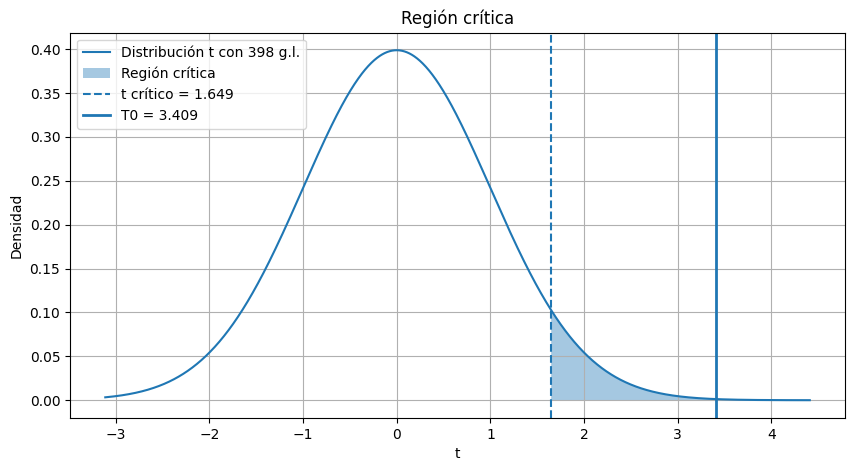

In [ ]:
alpha = 0.05
gl = n_E + n_NE - 2

t_critico = t.ppf(1 - alpha, gl)

# Rango más amplio, considerando T0
limite_izq = min(t.ppf(0.001, gl), T0 - 1)
limite_der = max(t.ppf(0.999, gl), T0 + 1)

x = np.linspace(limite_izq, limite_der, 2000)
y = t.pdf(x, gl)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label=f"Distribución t con {gl} g.l.")

# Región crítica
x_crit = np.linspace(t_critico, limite_der, 500)
y_crit = t.pdf(x_crit, gl)
plt.fill_between(x_crit, y_crit, alpha=0.4, label="Región crítica")

# Valor crítico
plt.axvline(t_critico, linestyle="--", label=f"t crítico = {t_critico:.3f}")

# T0 observado
plt.axvline(T0, linestyle="-", linewidth=2, label=f"T0 = {T0:.3f}")

plt.title("Región crítica")
plt.xlabel("t")
plt.ylabel("Densidad")
plt.legend()
plt.grid(True)
plt.show()

Al entrar $T_0$ en la región crítica, se rechaza $H_0$, de esta forma, al nivel de significancia de $\alpha = 0,05$, se entrega evidencia de que el promedio de estrés del grupo de los estudiantes, es mayor al de los no estudiantes suponiendo varianza poblacional desconocida pero igual.

Luego, se debe calcular el $p-value$, el cual se calcula de la siguiente forma

$$
p-value = P(T\geq T_0 | H_0)
$$

Es decir, la probabilidad de obtener un valor más extremo que el $T_0$ calculado, bajo el supuesto de que $H_0$ es verdadero. Dado que $T_0$ sigue una distribución t-student con 398 grados de libertad y $α = 0,05$, el $p-value$ se puede calcular de la siguiente forma.

$$
p-value = 1 - F_t(T_0)
$$

Donde $F_t$ es la función de probabilidad acumulada para la distribución discutida. Se procede a calcular dicho valor.

In [ ]:
p_value = 1 - t.cdf(T0, gl)
print(p_value)

0.0003593985782560649


De esta forma, se obtiene un valor de

$$
p_{value} = 0.00035939
$$

El cual es mucho menor que el nivel de significancia $\alpha = 0,05$, así, de esta forma también se rechaza $H_0$ llegando a las mismas conclusiones discutidas en el método anterior.

En cuanto a los errores de tipo I y tipo II. Cometer el primero corresponde a rechazar la hipótesis nula cuando es verdadera, aplicado a nuestra situación, significaría que no hay diferencias entre las medias. Un error del tipo II, corresponde a no rechazar la hipótesis nula cuando es falsa, en nuestro caso, sería quedarnos con que las medias iguales, cuando en realidad si ocurría que había una diferencia.

En nuestro caso, lo grave sería un error del tipo I, dado que significa que se estaba buscando una diferencia entre los grupos, y se afirmó una diferencia entre ellos, cuando en realidad nunca hubo una diferencia, por lo que las ocupaciones no serían un determinante a la hora de analizar los niveles de estrés.

Calculando el intervalo de confianza primero, con varianza igual, pero desconocida de la siguiente forma

$$
IC_{0.95}(\mu_E-\mu_{NE})
=
(\bar X_E-\bar X_{NE})
\pm
t_{0.025,\;n_E+n_{NE}-2}
\,S_p\,
\sqrt{
\frac{1}{n_E}
+
\frac{1}{n_{NE}}
}
$$

Su gráfico sería el siguiente

Diferencia de medias: 0.7961021976970439
Límite inferior IC 95%: 0.3369864539219255
Límite superior IC 95%: 1.2552179414721625


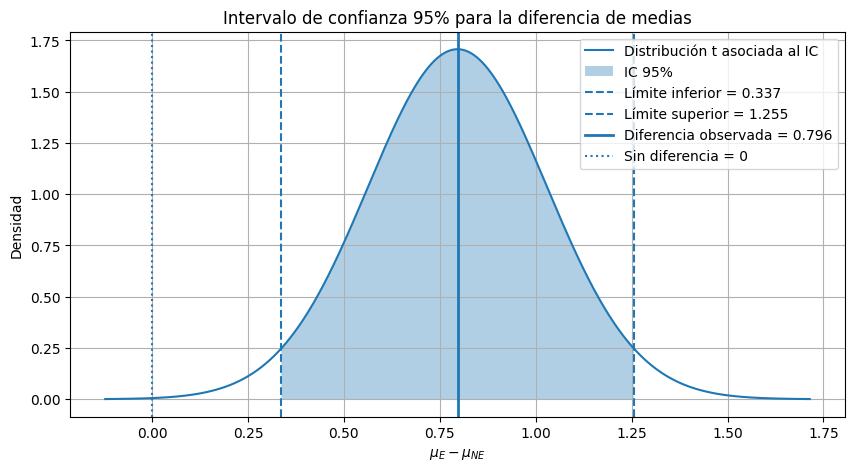

In [ ]:
alpha = 0.05
gl = n_E + n_NE - 2

# Diferencia observada
d = x_E - x_NE

# Valor crítico para IC bilateral 95%
t_critico = t.ppf(1 - alpha/2, gl)

# Error del intervalo
error = t_critico * S_p * np.sqrt((1/n_E) + (1/n_NE))

# Límites del IC
ic_inf = d - error
ic_sup = d + error

print("Diferencia de medias:", d)
print("Límite inferior IC 95%:", ic_inf)
print("Límite superior IC 95%:", ic_sup)

# Rango para graficar
x = np.linspace(ic_inf - error, ic_sup + error, 1000)

# Distribución t centrada en la diferencia observada
escala = S_p * np.sqrt((1/n_E) + (1/n_NE))
y = t.pdf((x - d) / escala, gl) / escala

plt.figure(figsize=(10, 5))

plt.plot(x, y, label="Distribución t asociada al IC")

# Área del intervalo de confianza
x_ic = np.linspace(ic_inf, ic_sup, 500)
y_ic = t.pdf((x_ic - d) / escala, gl) / escala
plt.fill_between(x_ic, y_ic, alpha=0.35, label="IC 95%")

# Límites del IC
plt.axvline(ic_inf, linestyle="--", label=f"Límite inferior = {ic_inf:.3f}")
plt.axvline(ic_sup, linestyle="--", label=f"Límite superior = {ic_sup:.3f}")

# Diferencia observada
plt.axvline(d, linestyle="-", linewidth=2, label=f"Diferencia observada = {d:.3f}")

# Línea de referencia 0
plt.axvline(0, linestyle=":", label="Sin diferencia = 0")

plt.title("Intervalo de confianza 95% para la diferencia de medias")
plt.xlabel(r"$\mu_E - \mu_{NE}$")
plt.ylabel("Densidad")
plt.legend()
plt.grid(True)
plt.show()

Si se asumiese varianza conocida, el estadístico a usar cambiaría, ahora se usaría una distribución normal estándar $Z$, la que sigue la siguiente ecuación

$$
IC_{0.95}(\mu_E-\mu_{NE})
=
\left[
(\bar X_E-\bar X_{NE})
-
z_{0.025}
\sqrt{
\frac{\sigma_E^2}{n_E}
+
\frac{\sigma_{NE}^2}{n_{NE}}
},
\;
(\bar X_E-\bar X_{NE})
+
z_{0.025}
\sqrt{
\frac{\sigma_E^2}{n_E}
+
\frac{\sigma_{NE}^2}{n_{NE}}
}
\right]
$$

En este caso, se asumirá varianza conocida, sin embargo, no se posee información real del dato poblacional, por lo que se estimará con la varianza muestral, la cual será útil sólo de forma ilustrativa y comparativa con el caso de varianza desconocida pero igual, pero no para llegar a conclusiones reales debido al desconocimiento de este parámetro.

Diferencia de medias: 0.7961021976970439
IC 95% aproximado con normal: (np.float64(0.3587486679056777), np.float64(1.2334557274884101))


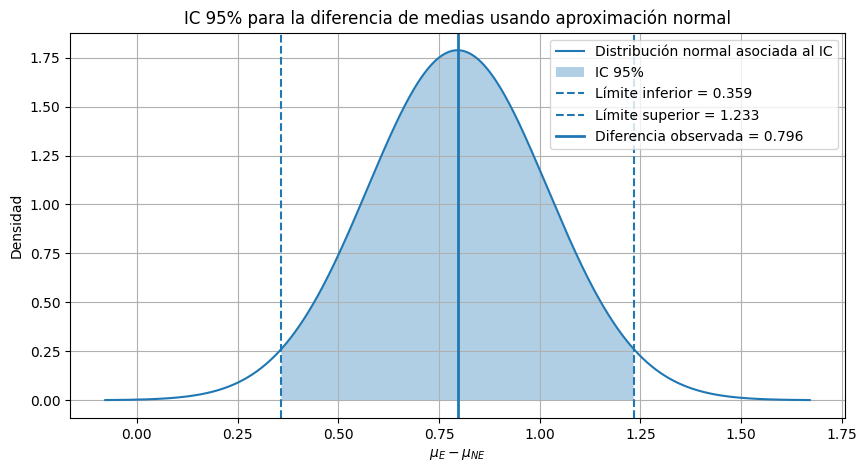

In [ ]:
alpha = 0.05

# Diferencia observada
d = x_E - x_NE

# Usamos varianzas muestrales como aproximación ilustrativa
sigma_E2 = S_E2
sigma_NE2 = S_NE2

# Error estándar
se = np.sqrt((sigma_E2 / n_E) + (sigma_NE2 / n_NE))

# Valor crítico normal
z_critico = norm.ppf(1 - alpha/2)

# Error del IC
error = z_critico * se

# Límites del IC
ic_inf = d - error
ic_sup = d + error

print("Diferencia de medias:", d)
print("IC 95% aproximado con normal:", (ic_inf, ic_sup))

# Rango para graficar
x = np.linspace(ic_inf - error, ic_sup + error, 1000)

# Distribución normal centrada en la diferencia observada
y = norm.pdf(x, loc=d, scale=se)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label="Distribución normal asociada al IC")

# Área del IC
x_ic = np.linspace(ic_inf, ic_sup, 500)
y_ic = norm.pdf(x_ic, loc=d, scale=se)
plt.fill_between(x_ic, y_ic, alpha=0.35, label="IC 95%")

# Límites del IC
plt.axvline(ic_inf, linestyle="--", label=f"Límite inferior = {ic_inf:.3f}")
plt.axvline(ic_sup, linestyle="--", label=f"Límite superior = {ic_sup:.3f}")

# Diferencia observada
plt.axvline(d, linestyle="-", linewidth=2, label=f"Diferencia observada = {d:.3f}")

plt.title("IC 95% para la diferencia de medias usando aproximación normal")
plt.xlabel(r"$\mu_E - \mu_{NE}$")
plt.ylabel("Densidad")
plt.legend()
plt.grid(True)
plt.show()

Los intervalos obtenidos bajo varianza conocida y varianza desconocida son similares, lo que indica que el tamaño muestral es suficientemente grande para que la distribución t-Student se aproxime a la normal. Aun así, como las varianzas poblacionales reales no son conocidas, el intervalo más apropiado teóricamente es el basado en t-Student con varianza combinada.

## Test de proporciones

Se decidió evaluar si el uso excesivo de pantallas aumenta el riesgo de sufrir estrés crítico. Para ello, se llevará a cabo un test de proporciones con dos muestras, que corresponden uso alto de pantallas($>6$ horas) y uso bajo de pantallas($\le 6$ horas). Por lo tanto, la hipótesis nula y la hipótesis alternativa quedan definidas de la siguiente forma:

$$
H_0: p_{\text{alto}} = p_{\text{bajo}}
$$

$$
H_1: p_{\text{alto}} > p_{\text{bajo}}
$$



Se utilizará el estadístico $Z$ con una aproximación a la normal, debido a la amplitud de la muestra. Se definirá un nivel de significancia de $α = 0,05$. De esta forma, la distribución teórica del estadístico sigue la siguiente ecuación:

<br>
$$
Z=
\frac{
(\hat p_{\text{alto}}-\hat p_{\text{bajo}}) - (p_{\text{alto}}-p_{\text{bajo}})
}
{
\sqrt{\hat p(1 - \hat p)
(\frac{1}{n_{\text{alto}}}
+
\frac{1}{n_{\text{bajo}}})
}
}
\sim
N(0,1)
$$
<br>

Donde $\hat p$ corresponde a la proporción combinada de estrés crítico en ambas muestras, que fue calculada de la siguiente forma, siendo $X$ el número de individuos con estrés crítico en su respectivo grupo:

<br>
$$
\hat p=
\frac{
  X_{\text{alto}} + X_{\text{bajo}}
}
{
  n_{\text{alto}} + n_{\text{bajo}}
}
$$
<br>

Luego, bajo la hipótesis nula $H_0$, el estadístico $Z$ se simplifica a la siguiente ecuación:

<br>
$$
Z=
\frac{
\hat p_{\text{alto}}-\hat p_{\text{bajo}}
}
{
\sqrt{\hat p(1 - \hat p)
(\frac{1}{n_{\text{alto}}}
+
\frac{1}{n_{\text{bajo}}})
}
}
\sim
N(0,1)
$$
<br>

A continuación se procederá con la preparación de los datos. Se categorizará el tiempo en pantalla para segmentar los dos grupos de interés y se contabilizarán las incidencias de estrés crítico en cada uno.

In [ ]:
# Separación por grupos
bajo_tiempo_pantalla = df[df["screen_time_hours"] <= 6]
alto_tiempo_pantalla = df[df["screen_time_hours"] > 6]

# Tamaño muestral de cada grupo
n_bajo = len(bajo_tiempo_pantalla)
n_alto = len(alto_tiempo_pantalla)

# Estresados por grupo
estresados_bajo = (bajo_tiempo_pantalla["stress_level_0_10"] >= 8).sum()
estresados_alto = (alto_tiempo_pantalla["stress_level_0_10"] >= 8).sum()

# Porporciones por grupo
prop_bajo = estresados_bajo / n_bajo
prop_alto = estresados_alto / n_alto

A partir de estos resultados se tiene que:


- $n_{alto} = 357$
- $n_{bajo} = 43$
- $ X_{alto} = 246$
- $ X_{bajo} = 3$
- $\hat p_{alto} = 0.689075$
- $\hat p_{bajo} = 0.069767$

Luego, es posible calcular la proporción combinada y la desviación estándar:

In [ ]:
# Proporción combinada
prop_combinada = (estresados_alto + estresados_bajo) / (n_alto + n_bajo)

# Desviación estándar
desviacion_estandar = np.sqrt(prop_combinada * (1 - prop_combinada) * ((1 / n_alto) + (1 / n_bajo)))

Se obtuvieron los siguientes valores:
- $\hat p = 0.6225$
- $σ = 0.0782$

Entonces, ahora es posible calcular el estadístico Z:

In [ ]:
z = (prop_alto - prop_bajo) / desviacion_estandar

Finalmente $Z = 7.914381$.

Dado que se estableció una significancia $α = 0.05$, la región crítica está definida por todos los valores del estadístico $Z$ que sean mayores o iguales a $1.645$. Es decir:

<br>
$$
Z_0 > 1.645
$$
<br>

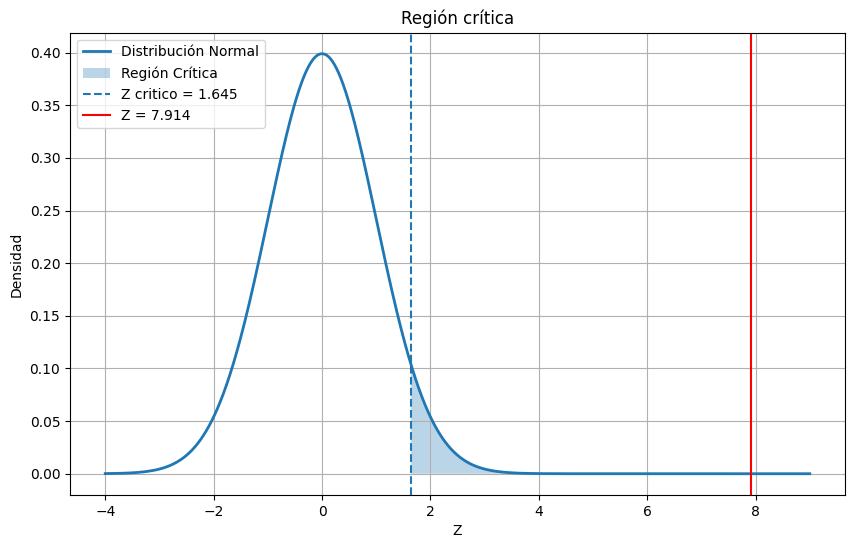

In [ ]:
import scipy.stats as stats

z_critico = 1.645

x = np.linspace(-4, 9, 1000)
y = stats.norm.pdf(x, 0, 1)

plt.figure(figsize=(10, 6))
plt.plot(x, y, linewidth=2, label="Distribución Normal")


x_crit = np.linspace(z_critico, 9, 500)
y_crit= stats.norm.pdf(x_crit, 0, 1)
plt.fill_between(x_crit, y_crit, alpha=0.3, label="Región Crítica")


plt.axvline(z_critico, linestyle='--', label=f'Z critico = {z_critico}')

plt.axvline(z, color="red", label=f'Z = {z:.3f}')


plt.title("Región crítica")
plt.xlabel("Z")
plt.ylabel("Densidad")
plt.legend()
plt.grid(True)
plt.show()

A partir de la gráfica es posible notar que $Z$ está dentro de la región crítica y, por lo tanto, se rechaza la hipótesis nula, lo que indica las personas que superan las 6 horas de tiempo en pantalla presentan una probabilidad significativamente mayor de desarrollar cuadros de estrés crítico en comparación con aquellos que mantienen un uso moderado.

Luego, es posible obtener el p-value, el cual determina la probabilidad de obtener un estadístico más extremo que el calculado, bajo el supuesto de que $H_0$ es verdadero. Es decir:

<br>
$$
p-value = P(Z \geq Z_{obs} | H_0)
$$
<br>

Dado que Z sigue una distribución normal estándar, la ecuación es equivalente a:

<br>
$$
p-value = 1 - Φ(Z_{obs})
$$
<br>

Que se calcula a continuación:

In [ ]:
p_value_prop = 1 - stats.norm.cdf(z)

print(p_value_prop)

1.2212453270876722e-15


Es posible notar que el p-value es considerablemente menor que la significancia, lo que reafirma el rechazo hacia la hipótesis nula.

# Regresión Lineal

Para realizar la regresión lineal entre una variable dependiente $y$ y una o más variables independientes $x$, se utilizó el método de los mínimos cuadrados. Consistente en determinar la siguiente ecuación de la recta:

<br>
$$
y = θ_0 + θ_1x
$$
<br>

Con $θ_0$ y $θ_1$ coeficientes de la ecuación, correspondientes al intercepto y a la pendiente de la recta. Para hallar sus valores específicos, es necesario calcular la ecuación normal, dada por:

<br>
$$
θ = (X^TX)^{-1}X^Ty
$$
<br>

Con $y$ el vector columna que representa los datos de la variable dependiente  y $X$ una matriz cuya primera columna está compuesta de unos, lo que permite obtener el intercepto y su segunda columna compuesta por los valores obtenidos para la variable independiente.

El coeficiente de determinación $R^2$ permite evaluar qué tan buena es la predicción de un modelo estadístico. Se calcula como:

<br>
$$
R^2 = 1 -
\frac
{
SSE
}
{
SST
}
$$
<br>

Donde $SSE$ es la suma de cuadrados totales:

<br>
$$
SSE = \sum_{i=1}^{n} (y_i - \bar y_i)^2
$$
<br>

y $SST$ es la suma de cuadrados del error:

<br>
$$
SST = \sum_{i=1}^{n} (y_i - \hat y_i)^2
$$
<br>

Para calcular los p-values se debe realizar un test t, donde $H_0$ corresponde a que los coeficientes tienen un valor nulo. Para ello se obtiene el estadístico t:

<br>
$$
t = \frac
{
  \hat θ
}
{
  SE(\hat θ)
}
\sim
T_{n-2}
$$
<br>

Donde $SE(\hat θ)$ es el error estándar asociaado al coeficiente:

<br>
$$
SE(\hat θ) =
\sqrt
{
  \frac
{
  \frac{SSE}{n-2}
}
{
  \sum_{i=1}^{n} (x_i - \bar x)^2
}
}
$$
<br>

En caso de que el p-values del coeficiente sea menor a la significancia definida, en este caso $α=0.05$, se rechaza la hipótesis nula y es posible afirmar que el coeficiente es estadísticamente significativo.

## Regresión entre Tiempo en pantalla y Estrés

In [ ]:
arreglo_estres = df['stress_level_0_10'].to_numpy()
arreglo_pantallas = df['screen_time_hours'].to_numpy()

bias_pantallas = np.c_[np.ones(400), arreglo_pantallas]

theta = np.linalg.inv(bias_pantallas.T.dot(bias_pantallas)).dot(bias_pantallas.T).dot(arreglo_estres)
print(theta[0])
print(theta[1])

2.8544939067339117
0.5868215817644619


Los parámetros obtenidos fueron $θ_0 = 2.8544939$ y $θ_1 = 0.5868215$, por lo tanto, la ecuación de la recta para el estrés según el tiempo en pantalla es:

<br>
$$
y = 2.8544939 + 0.5868215x
$$
<br>

Es decir, se encontró una relación positiva entre el tiempo en pantalla y el nivel de estrés. Los coeficientes indican que, a medida que aumentan las horas frente a pantallas, también tienden a aumentar los niveles de estrés. La pendiente obtenida fue de 0.5868, lo que significa que, en promedio, por cada hora adicional de uso de pantallas, el nivel de estrés aumenta aproximadamente 0.59 puntos.

Se prosigue con el cálculo del coeficiente de determinación:


In [ ]:
y_pred = bias_pantallas.dot(theta)

y_promedio = np.mean(arreglo_estres)

SST = np.sum((arreglo_estres - y_promedio)**2)
SSE = np.sum((arreglo_estres - y_pred)**2)

R_2 = 1 - (SSE / SST)
print(R_2)

0.48694136300925417


El modelo obtuvo un coeficiente de determinación $R^2 = 0.4869413$, lo que indica que cerca del 48.7% de la variabilidad observada en los niveles de estrés puede explicarse por el tiempo en pantalla. Este resultado sugiere que existe una relación importante entre ambas variables, aunque también existen otros factores que influyen en el estrés y que no son considerados por este modelo.

In [ ]:
matriz_inversa = np.linalg.inv(bias_pantallas.T.dot(bias_pantallas))

varianza_thetas = (SSE/398) * np.diag(matriz_inversa)
error_estandar_thetas = np.sqrt(varianza_thetas)

t_stat = theta / error_estandar_thetas

p_values = stats.t.sf(np.abs(t_stat), df=398) * 2
print(p_values[0])
print(p_values[1])

1.6858376399771072e-21
1.2024981763314553e-59


Se tiene que:

- $\text{p_value}_{θ_0} = 1.6858376 * 10^{-21}$
- $\text{p_value}_{θ_1} = 1.2024981 * 10^{-59}$

Los p-values obtenidos son considerablemente menores al nivel de significancia utilizado ($α = 0.05$), por lo que se rechaza la hipótesis nula de ausencia de relación entre las variables. En consecuencia, existe evidencia estadísticamente significativa para afirmar que el tiempo en pantalla influye en los niveles de estrés de los individuos analizados.

/tmp/ipykernel_3157/3835017031.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x="screen_time_hours", y="stress_level_0_10", palette="viridis", data=df)


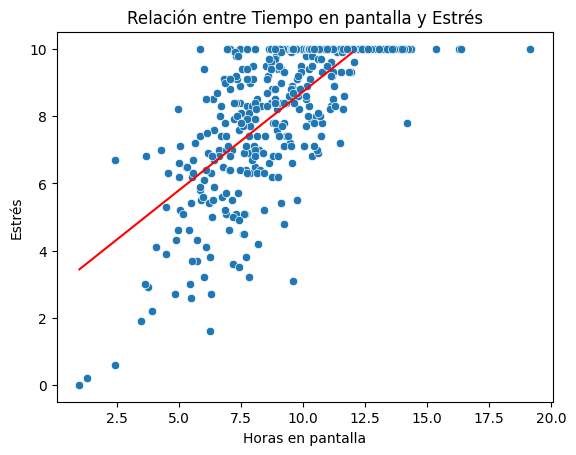

In [ ]:
sns.scatterplot(x="screen_time_hours", y="stress_level_0_10", palette="viridis", data=df)

x_lim = [1, 12]
x_lim_ones = np.c_[np.ones(2), x_lim]
y_lim = x_lim_ones.dot(theta)
plt.plot(x_lim, y_lim, 'r-')
plt.title("Relación entre Tiempo en pantalla y Estrés")
plt.xlabel("Horas en pantalla")
plt.ylabel("Estrés")

plt.show()

Finalmente, estos resultados son consistentes con los análisis realizados previamente mediante correlaciones, bootstrap y los test de hipótesis, los cuales mostraron una relación influyente entre el tiempo en pantalla y el estrés. En conjunto, la evidencia obtenida respalda la idea de que un mayor uso de pantallas se encuentra asociado a mayores niveles de estrés dentro de la población estudiada.

Al interpretar los resultados de la regresión, es importante considerar algunas fuentes de sesgo. En primer lugar, las horas en pantalla y los niveles de estrés fueron reportados por los propios participantes, por lo que pueden existir errores o diferencias en la percepción de cada persona. Además, el estrés depende de múltiples factores, como la carga académica o laboral, la situación personal y la calidad del sueño, variables que no fueron incluidas en el modelo. Finalmente, aunque se observó una relación positiva y significativa entre ambas variables, la regresión permite identificar asociación, pero no establecer una relación causal directa entre el tiempo en pantalla y el estrés.



Text(0, 0.5, 'Residuos')

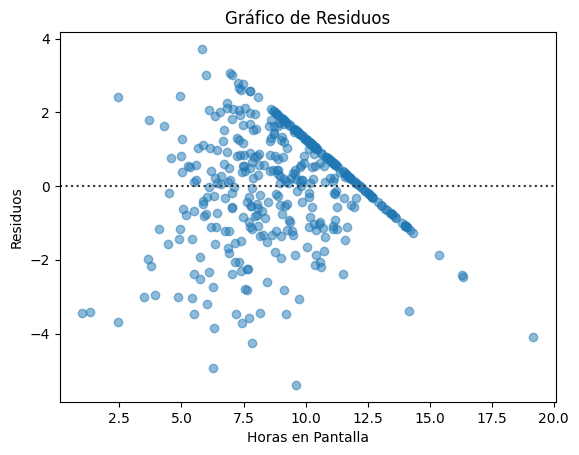

In [ ]:
sns.residplot(x=arreglo_pantallas, y=arreglo_estres, lowess=False, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red', 'linestyle': '--'})
plt.title('Gráfico de Residuos')
plt.xlabel('Horas en Pantalla')
plt.ylabel('Residuos')

El gráfico de residuos muestra que los errores se distribuyen en torno a cero sin evidenciar una tendencia curva clara, lo que respalda el uso de una regresión lineal para modelar la relación entre tiempo en pantalla y estrés. Sin embargo, se observa una limitación en los valores altos de estrés debido a que la variable está acotada entre 0 y 10, generando una concentración de residuos en la zona superior del gráfico. A pesar de ello, el modelo captura adecuadamente la tendencia general observada en los datos. En pocas palabras los residuos se distribuyen alrededor de cero y no presentan patrones curvos importantes, por lo que la regresión lineal resulta adecuada. La forma triangular observada se debe a que el estrés tiene un valor máximo de 10, lo que limita los posibles errores cuando las predicciones son altas.


## Regresión entre Horas de sueño y Estrés

In [ ]:
arreglo_estres = df['stress_level_0_10'].to_numpy()
arreglo_horas_sueno = df['sleep_hours'].to_numpy()

bias_horas_sueno = np.c_[np.ones(400), arreglo_horas_sueno]

theta = np.linalg.inv(bias_horas_sueno.T.dot(bias_horas_sueno)).dot(bias_horas_sueno.T).dot(arreglo_estres)
print(theta[0])
print(theta[1])

16.44291485408354
-1.1824052378677954


Los parámetros obtenidos fueron $θ_0 = 16.442915$ y $θ_1 = -1.1824052$, por lo tanto, la ecuación de la recta para el estrés según las horas de sueño es:

<br>
$$
y = 16.442915 - 1.1824052x
$$
<br>

Luego, se calcula el coeficiente de determinación:

In [ ]:
y_pred = bias_horas_sueno.dot(theta)

y_promedio = np.mean(arreglo_estres)

SST = np.sum((arreglo_estres - y_promedio)**2)
SSE = np.sum((arreglo_estres - y_pred)**2)

R_2 = 1 - (SSE / SST)
print(R_2)

0.23149278700897702


Obteniendose un $R^2 = 0.2314927$, indica que existen muchos factores que pueden influir en el estrés de las personas, sin embargo, también indica que las horas de sueño logran explicar un 23% de la varianza en los niveles de estrés.

Se calculan los p-values:

In [ ]:
matriz_inversa = np.linalg.inv(bias_horas_sueno.T.dot(bias_horas_sueno))

varianza_thetas = (SSE/398) * np.diag(matriz_inversa)
error_estandar_thetas = np.sqrt(varianza_thetas)

t_stat = theta / error_estandar_thetas

p_values = stats.t.sf(np.abs(t_stat), df=398) * 2
print(p_values[0])
print(p_values[1])

7.811249857678836e-69
1.4449929572988805e-24


Se tiene que:

- $\text{p_value}_{θ_0} = 7.8112498 * 10^{-69}$
- $\text{p_value}_{θ_1} = 1.4449929 * 10^{-24}$

Ambos p-values  arrojaron valores cuyos órdenes de magnitud son menores al nivel de significancia de 0.05. Esto permite rechazar la hipótesis nula, es decir, los coeficientes son estadísticamente significativos, confirmando la existencia de una relación inversa entre el descanso y el estrés.

/tmp/ipykernel_3157/370249463.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(x="sleep_hours", y="stress_level_0_10", palette="viridis", data=df)


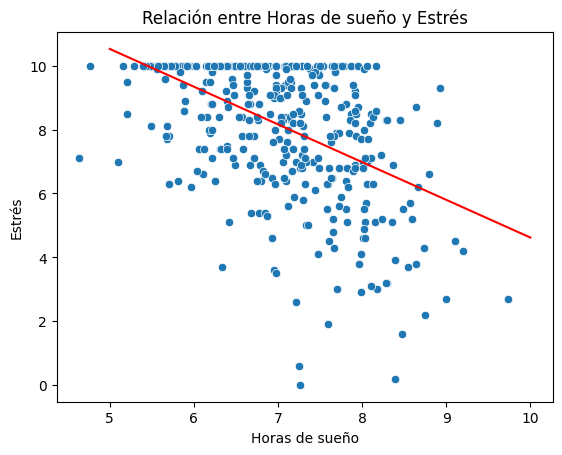

In [ ]:
sns.scatterplot(x="sleep_hours", y="stress_level_0_10", palette="viridis", data=df)

x_lim = [5, 10]
x_lim_ones = np.c_[np.ones(2), x_lim]
y_lim = x_lim_ones.dot(theta)
plt.plot(x_lim, y_lim, 'r-')
plt.title("Relación entre Horas de sueño y Estrés")
plt.xlabel("Horas de sueño")
plt.ylabel("Estrés")

plt.show()

Los resultados muestran una relación negativa de las horas de sueño sobre el estrés de las personas, mostrando una tendencia a la baja en los niveles de tensión, a medida que aumentan las horas de descanso. Lo que es coherente con lo obtenido en los intervalos de confianza para las correlaciones, donde al menos, en el grupo de estudiantes y en el de los empleados, el descanso tenía una relación negativa con el estrés, para todos los casos. A su vez, da cuenta que la tensión mantiene un nivel que está por sobre el moderado, incluso para aquellos que han dormido alrededor de 8 horas.

Text(0, 0.5, 'Residuos')

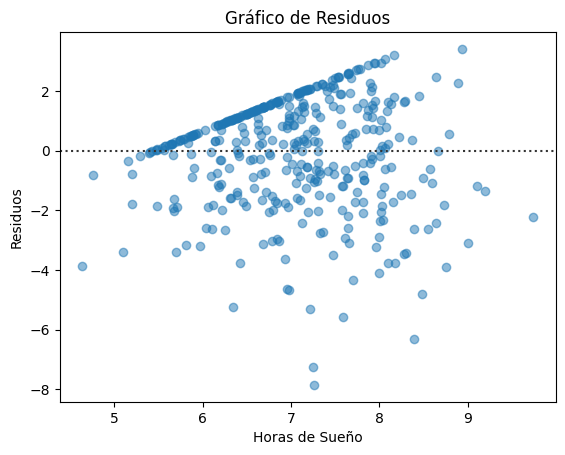

In [ ]:
sns.residplot(x=arreglo_horas_sueno, y=arreglo_estres, lowess=False, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red', 'linestyle': '--'})
plt.title('Gráfico de Residuos')
plt.xlabel('Horas de Sueño')
plt.ylabel('Residuos')

En el gráfico de residuos se evidencia una clara asimetría en la distribución de los errores. Mientras que los residuos positivos se encuentran fuertemente limitados, alcanzando un máximo cercano a +3, los residuos negativos presentan una dispersión mucho mayor, llegando hasta -8. Esto es una consecuencia directa de la alta concentración de datos en el nivel máximo, lo que genera un bloque continuo de residuos positivos concentrado.

Si bien el modelo realizado puede representar una aproximación del comportamiento del estrés a partir de las horas de sueño, este posee algunas limitaciones como la dependencia de la cantidad datos muestrales o el límite generado por una gran concentración de datos en el nivel máximo de estrés, lo que provoca cambios en la pendiente y es una posible fuente de sesgo.

# Modelo de Machine Learning

## Explicación problema y selección del modelo

Para esta sección, decidimos implementar un modelo que sea capaz de predecir la probabilidad de que un sujeto, con ciertas características, en este caso, calidad del sueño, horas en pantalla y su ocupación, fuera a poseer un nivel alto de estrés. Es decir, queremos que el modelo aprenda de la relación (calidad del sueño, horas en pantalla, ocupación) $\rightarrow$ nivel de estrés. Para ello, se utilizará el modelo de random forest.

Random Forest es un modelo de aprendizaje basado en la construcción de múltiples árboles de decisión. Cada árbol intenta clasificar una observación a partir de reglas generadas con las variables predictoras. En este caso, el objetivo es predecir si una persona presenta estrés alto utilizando su ocupación, calidad del sueño y horas en pantalla.

A diferencia de un único árbol de decisión, Random Forest construye muchos árboles usando muestras aleatorias del conjunto de entrenamiento. Luego, para clasificar una observación, cada árbol entrega una predicción y el modelo final decide mediante votación mayoritaria. Además, la probabilidad estimada de estrés alto puede interpretarse como la proporción de árboles que clasificaron esa observación como estrés alto.

Este enfoque permite reducir el sobreajuste de un árbol individual y capturar relaciones no necesariamente lineales entre las variables. Por ello, resulta adecuado para analizar cómo distintas combinaciones de ocupación, calidad del sueño y horas en pantalla se relacionan con la probabilidad de presentar estrés alto.

Cada árbol del Random Forest se construye aprendiendo reglas a partir de los datos de entrenamiento. Para esto, el algoritmo prueba distintas preguntas sobre las variables, como si la calidad del sueño es menor o igual a cierto valor, si las horas en pantalla superan cierto umbral o si la ocupación pertenece a una categoría específica. En cada paso, el árbol elige la pregunta que mejor separa los casos de estrés alto y estrés no alto. Este proceso se repite hasta formar hojas finales, donde la predicción corresponde a la clase más frecuente dentro de ese grupo.

## Construcción del modelo

Para construir el ambiente del modelo, se clasificará como estrés alto aquel que posea 8 o más puntos de estrés. Las variables de entrada serán las siguientes

- $X_1$ = Ocupación
- $X_2$ = Calidad del sueño
- $X_3$ = Horas en pantalla

Y una variable de salida, que sigue una bernoulli de tal forma que entrega 1 si la persona posee estrés alto, o cero en caso contrario.

$$
Y=
\begin{cases}
1 & \text{si estrés}\geq 8\\
0 & \text{si estrés}<8
\end{cases}
$$

In [ ]:
# Columnas a utilizar
col_estres = "stress_level_0_10"
col_ocupacion = "occupation"
col_sueno = "sleep_quality_1_5"
col_pantalla = "screen_time_hours"

# Variable objetivo: estrés alto
df["estres_alto"] = (df[col_estres] >= 8).astype(int)

# Variables predictoras
X = df[[col_ocupacion, col_sueno, col_pantalla]]
y = df["estres_alto"]

# Separación entrenamiento/prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Preprocesamiento de la variable categórica
preprocesamiento = ColumnTransformer(
    transformers=[
        ("ocupacion", OneHotEncoder(handle_unknown="ignore"), [col_ocupacion])
    ],
    remainder="passthrough"
)

# Modelo Random Forest
modelo_rf = Pipeline(
    steps=[
        ("preprocesamiento", preprocesamiento),
        ("modelo", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

# Entrenamiento
modelo_rf.fit(X_train, y_train)

# Predicciones
y_pred = modelo_rf.predict(X_test)
y_prob = modelo_rf.predict_proba(X_test)[:, 1]

## Resultados

El modelo Random Forest obtuvo una exactitud del 80% sobre el conjunto de prueba, clasificando correctamente 64 de las 80 observaciones evaluadas. La matriz de confusión muestra una distribución equilibrada de errores, con ocho falsos positivos y ocho falsos negativos. Además, para la categoría de estrés alto, el modelo alcanzó una precisión y sensibilidad de 84%, indicando una buena capacidad para identificar individuos con niveles elevados de estrés utilizando únicamente la ocupación, la calidad del sueño y las horas en pantalla. Estos resultados sugieren que las variables seleccionadas contienen información relevante para la predicción del estrés alto y que el modelo presenta un desempeño adecuado para fines exploratorios.

In [ ]:
# Predicciones sobre el conjunto de prueba
y_pred = modelo_rf.predict(X_test)

# Probabilidad estimada de estrés alto
y_prob = modelo_rf.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8

Matriz de confusión:
[[22  8]
 [ 8 42]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.73      0.73      0.73        30
           1       0.84      0.84      0.84        50

    accuracy                           0.80        80
   macro avg       0.79      0.79      0.79        80
weighted avg       0.80      0.80      0.80        80



## Observaciones extra

La variable con mayor capacidad predictiva para identificar estrés alto es la cantidad de horas en pantalla, concentrando cerca del 80% de la importancia total del modelo. La calidad del sueño también contribuye a la predicción, aunque en menor medida, mientras que la ocupación presenta una influencia relativamente reducida.

En cuanto a la distribución de probabilidades, podemos notar que en su mayoría las probabilidades o son cercanas al cero o son cercanas al 1, por lo que tiene pocos valores de indecisión, es decir cercanos al 0,5, por lo que el modelo suele tomar decisiones con confianza en ellas con regularidad.

Por último, para la curva ROC se puede extraer que si se selecciona aleatoriamente una persona con estrés alto y una con estrés no alto, existe aproximadamente un 85.2% de probabilidad de que el modelo asigne una puntuación de riesgo mayor a la persona que realmente presenta estrés alto.

### Importancia de variables

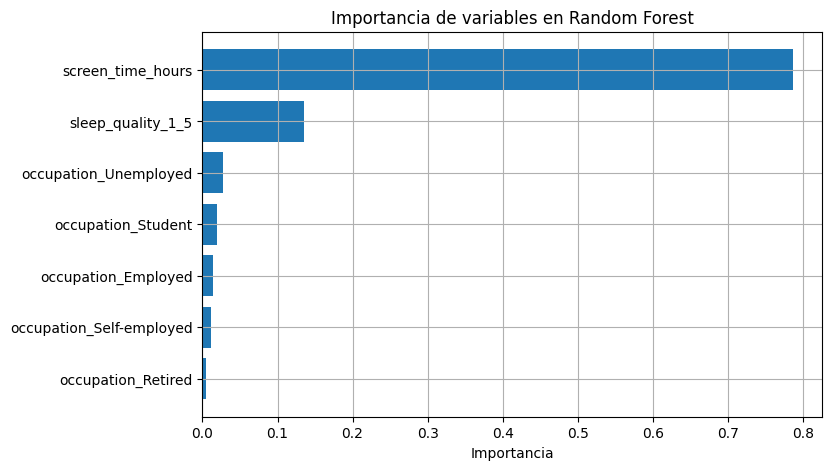

In [ ]:
# Obtener nombres de variables después del OneHotEncoder
nombres_ocupacion = modelo_rf.named_steps["preprocesamiento"] \
    .named_transformers_["ocupacion"] \
    .get_feature_names_out([col_ocupacion])

nombres_variables = list(nombres_ocupacion) + [col_sueno, col_pantalla]

importancias = modelo_rf.named_steps["modelo"].feature_importances_

indices = np.argsort(importancias)

plt.figure(figsize=(8, 5))
plt.barh(np.array(nombres_variables)[indices], importancias[indices])
plt.xlabel("Importancia")
plt.title("Importancia de variables en Random Forest")
plt.grid(True)
plt.show()

### Distribución de probabilidades predichas

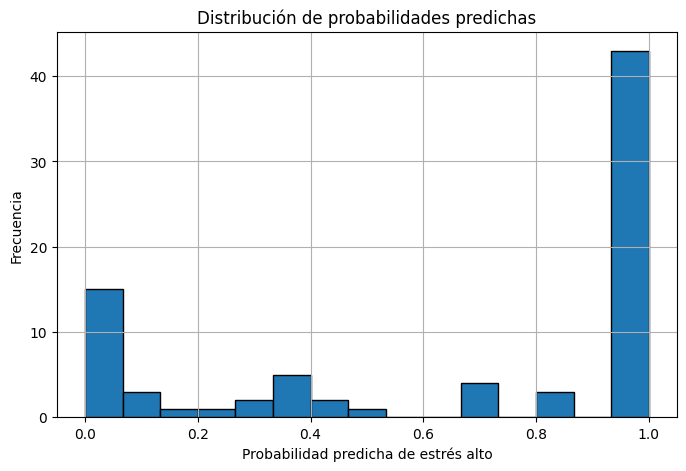

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(y_prob, bins=15, edgecolor="black")

plt.xlabel("Probabilidad predicha de estrés alto")
plt.ylabel("Frecuencia")
plt.title("Distribución de probabilidades predichas")
plt.grid(True)
plt.show()

### Curva ROC

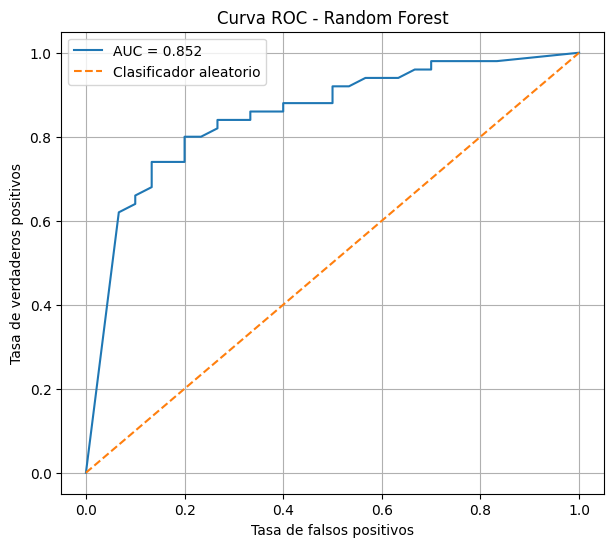

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Clasificador aleatorio")

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC - Random Forest")
plt.legend()
plt.grid(True)
plt.show()